# Gemma 3 27B IT Zero-Shot Evaluation

## 1. Model & Experiment Overview

Gemma 3 27B IT is an instruction-tuned generative model from Google. In this text-only experiment, it received a single instruction and a math word problem and generated an `ANSWERABLE` or `UNANSWERABLE` label. The task used zero-shot prompting without demonstrations or task-specific fine-tuning. This notebook reads the saved run artifacts.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks').is_dir() and (path / 'data/processed').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')

RESULTS_DIR = PROJECT_ROOT / 'results/llm/gemma-3-27b-it'
RUN_ID = 'run_01'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
PREDICTED_LABELS = [*LABELS, 'INVALID']
METRICS = {
    'Accuracy': 'accuracy',
    'Precision (UNANSWERABLE)': 'precision_unanswerable',
    'Recall (UNANSWERABLE)': 'recall_unanswerable',
    'F1 (UNANSWERABLE)': 'f1_unanswerable',
}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def load_evaluation(dataset, expected_examples, identifier):
    directory = RESULTS_DIR / dataset / RUN_ID
    metrics = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
    run = metrics['run']
    predictions = pd.read_csv(
        directory / 'predictions.csv', keep_default_na=False,
        dtype={identifier: str, 'raw_response': str, 'text': str},
    )
    expected_columns = {'row_index', identifier, 'text', 'true_label',
                        'raw_response', 'prediction', 'hit_token_limit'}
    if not expected_columns.issubset(predictions):
        raise ValueError(f'{directory}: predictions CSV lacks required columns')
    if (predictions['row_index'].tolist() != list(range(expected_examples))
            or predictions[identifier].eq('').any()
            or not predictions['true_label'].isin(LABELS).all()
            or not predictions['prediction'].isin(PREDICTED_LABELS).all()):
        raise ValueError(f'{directory}: unexpected prediction rows or labels')
    parsed = predictions['raw_response'].str.strip()
    parsed = parsed.where(parsed.isin(LABELS), 'INVALID')
    if not parsed.eq(predictions['prediction']).all():
        raise ValueError(f'{directory}: raw responses and recorded labels disagree')
    reconstructed = pd.crosstab(predictions['true_label'], predictions['prediction']).reindex(
        index=LABELS, columns=PREDICTED_LABELS, fill_value=0,
    )
    if reconstructed.values.tolist() != matrix.values.tolist():
        raise ValueError(f'{directory}: prediction counts disagree with the matrix')

    if run['model_id'] != 'google/gemma-3-27b-it':
        raise ValueError(f'{directory}: unexpected model identity')
    if (run['dataset'], run['run_id'], metrics['positive_class']) != (dataset, RUN_ID, LABELS[1]):
        raise ValueError(f'{directory}: unexpected run identity or positive class')
    if (list(matrix.index) != LABELS or list(matrix.columns) != PREDICTED_LABELS
            or metrics['confusion_matrix_rows'] != LABELS
            or metrics['confusion_matrix_columns'] != PREDICTED_LABELS):
        raise ValueError(f'{directory}: unexpected matrix labels or order')
    if (not all(pd.api.types.is_integer_dtype(dtype) for dtype in matrix.dtypes)
            or (matrix < 0).any().any() or matrix.values.tolist() != metrics['confusion_matrix']):
        raise ValueError(f'{directory}: CSV and JSON confusion counts disagree or are invalid')
    if not (matrix.values.sum() == metrics['num_examples'] == run['row_count'] == expected_examples):
        raise ValueError(f'{directory}: unexpected number of examples')

    tn, fp, invalid_negative = matrix.loc[LABELS[0]]
    fn, tp, invalid_positive = matrix.loc[LABELS[1]]
    missed = fn + invalid_positive

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    expected = {
        'accuracy': (tn + tp) / expected_examples,
        'precision_unanswerable': ratio(tp, tp + fp),
        'recall_unanswerable': ratio(tp, tp + missed),
        'f1_unanswerable': ratio(2 * tp, 2 * tp + fp + missed),
        'num_invalid': invalid_negative + invalid_positive,
        'invalid_rate': (invalid_negative + invalid_positive) / expected_examples,
    }
    for key, value in expected.items():
        if not math.isclose(metrics[key], value, rel_tol=0, abs_tol=1e-12):
            raise ValueError(f'{directory}: {key} disagrees with the saved confusion counts')
    return metrics, matrix, predictions


sum_metrics, sum_matrix, sum_predictions = load_evaluation('sum', 10944, 'pair_id')
umwp_metrics, umwp_matrix, umwp_predictions = load_evaluation('umwp', 5200, 'id')

In [2]:
settings = {
    'Model': 'model_id',
    'Model type': 'model_type',
    'Architecture': 'model_architectures',
    'Model API': 'model_api',
    'Processor API': 'processor_api',
    'Weights path': 'model_path',
    'Chat template': 'chat_template',
    'Precision': 'dtype',
    'Quantization': 'quantization',
    'GPU': 'gpu',
    'Requested temperature': 'requested_temperature',
    'Sampling enabled': 'do_sample',
    'Number of beams': 'num_beams',
    'Maximum new tokens': 'max_new_tokens',
    'PyTorch': 'torch_version',
    'Transformers': 'transformers_version',
    'CUDA': 'cuda_version',
}
run = sum_metrics['run']
for key in (*settings.values(), 'prompt', 'model_sha256', 'evaluator_sha256',
            'shared_evaluator_sha256', 'transformers_distribution_url', 'invalid_output_policy'):
    if run[key] != umwp_metrics['run'][key]:
        raise ValueError(f'Saved runs disagree on {key}')

configuration = {
    label: 'None' if run[key] is None else str(run[key])
    for label, key in settings.items()
}
configuration['Decoding'] = 'Greedy' if not run['do_sample'] and run['num_beams'] == 1 else 'See settings'
vcs = (run['transformers_distribution_url'] or {}).get('vcs_info') or {}
configuration['Transformers source commit'] = vcs.get('commit_id', 'Unavailable')
display(pd.Series(configuration, name='Recorded setting').rename_axis('Setting').to_frame())
display(Markdown('**Exact prompt**\n\n```text\n' + run['prompt'] + '\n```'))

fingerprints = {
    'Model SHA-256': run['model_sha256'],
    'Evaluator SHA-256': run['evaluator_sha256'],
    'Shared evaluator SHA-256': run['shared_evaluator_sha256'],
    **{f"{name} dataset SHA-256 ({metrics['run']['run_id']})": metrics['run']['dataset_sha256']
       for name, metrics in [('SUM Test', sum_metrics), ('UMWP', umwp_metrics)]},
}
display(pd.Series(fingerprints, name='Recorded value').rename_axis('Fingerprint').to_frame())

,Recorded setting
Setting,
Model,google/gemma-3-27b-it
Model type,gemma3
Architecture,['Gemma3ForConditionalGeneration']
Model API,Gemma3ForConditionalGeneration
Processor API,AutoProcessor
Weights path,models/gemma-3-27b-it
Chat template,"Gemma processor native chat template, one text..."
Precision,bfloat16
Quantization,None


**Exact prompt**

```text
Determine whether the following math problem can be answered using the information provided.

Respond with exactly one label:
ANSWERABLE or UNANSWERABLE.

Do not solve the problem or provide an explanation.

Math problem:
{question}

Label:
```

,Recorded value
Fingerprint,
Model SHA-256,32c2327173a351658094430eb445b8d3371eb70ef6b5f4...
Evaluator SHA-256,49bb6d61c5046406d283edc1b0e503c1c81b54de5018b7...
Shared evaluator SHA-256,292e98e5db749939399e3fea2a6279fd99648160577d96...
SUM Test dataset SHA-256 (run_01),c1e4bac1e1d1f27ab8a6408ac68ae710faf521822bff49...
UMWP dataset SHA-256 (run_01),92df3bed2d3cee139c6ddbca2673fca0a1687aa9f90b3c...


## 2. Evaluation Metrics

**UNANSWERABLE is the positive class.**

- **Accuracy** is the fraction of all questions assigned the correct label.
- **Precision** is the fraction of predicted UNANSWERABLE questions that are truly unanswerable.
- **Recall** is the fraction of truly unanswerable questions detected by the model.
- **F1** is the harmonic mean of precision and recall for UNANSWERABLE.

Confusion matrices show actual labels in rows and predicted labels in columns. A false positive flags an answerable question as unanswerable. A false negative marks an unanswerable question as answerable, which can lead a downstream solver to attempt a question with insufficient information. The INVALID column tracks responses outside the two permitted labels. Each heatmap scales its colors to its own counts.

In [3]:
if sum_metrics['invalid_output_policy'] != umwp_metrics['invalid_output_policy']:
    raise ValueError('Saved runs disagree on the invalid-output policy')
display(Markdown('**Recorded scoring policy.** ' + sum_metrics['invalid_output_policy']))


def show_evaluation(name, metrics, matrix):
    summary = {
        'Examples': f"{metrics['num_examples']:,}",
        **{label: f'{metrics[key]:.6f}' for label, key in METRICS.items()},
        'Invalid outputs': f"{metrics['num_invalid']:,} ({metrics['invalid_rate']:.2%})",
    }
    display(pd.DataFrame([summary], index=pd.Index([name], name='Dataset')))

    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    values = matrix.to_numpy()
    limit = values.max()
    ax.imshow(values, cmap='Blues', vmin=0, vmax=limit, aspect='auto')
    for (row, column), value in matrix.stack().items():
        ax.text(matrix.columns.get_loc(column), matrix.index.get_loc(row), f'{value:,}',
                ha='center', va='center', color='white' if value > limit / 2 else 'black')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted label', ylabel='Actual label', title=f'{name} confusion matrix')
    plt.show()
    plt.close(fig)


def show_class_errors(matrix):
    support = matrix.sum(axis=1)
    correct = pd.Series([matrix.loc[label, label] for label in LABELS], index=LABELS)
    wrong_label = pd.Series(
        [matrix.loc[LABELS[0], LABELS[1]], matrix.loc[LABELS[1], LABELS[0]]],
        index=LABELS,
    )
    errors = pd.DataFrame({
        'Actual examples': support,
        'Correct': correct,
        'Wrong label': wrong_label,
        'INVALID': matrix['INVALID'],
        'Wrong-label rate': (wrong_label / support).map('{:.2%}'.format),
        'Total error rate': ((wrong_label + matrix['INVALID']) / support).map('{:.2%}'.format),
    })
    display(errors.rename_axis('Actual class'))


def interpret_errors(matrix):
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    support = matrix.sum(axis=1)
    return (
        f'There were **{fp:,} false positives** ({fp / support["ANSWERABLE"]:.2%} '
        f'of answerable questions) and **{fn:,} false negatives** '
        f'({fn / support["UNANSWERABLE"]:.2%} of unanswerable questions). '
        f'Of the true UNANSWERABLE rows, {matrix.loc["UNANSWERABLE", "INVALID"]:,} '
        'additionally received INVALID responses and count as missed positives in recall.'
    )


def show_examples(predictions, identifier):
    false_positives = predictions['true_label'].eq('ANSWERABLE') & predictions['prediction'].eq('UNANSWERABLE')
    false_negatives = predictions['true_label'].eq('UNANSWERABLE') & predictions['prediction'].eq('ANSWERABLE')
    categories = {
        'False positive': false_positives,
        'False negative': false_negatives,
        'INVALID': predictions['prediction'].eq('INVALID'),
    }
    columns = ['row_index', identifier, 'text', 'true_label', 'prediction', 'raw_response', 'hit_token_limit']
    examples = pd.concat(
        [predictions.loc[mask, columns].head(1).assign(error=label) for label, mask in categories.items()],
        ignore_index=True,
    )
    # repr keeps empty strings, trailing whitespace and newlines visible.
    examples['raw_response'] = examples['raw_response'].map(repr)
    if examples.empty:
        display(Markdown('No recorded errors in these categories.'))
    else:
        display(examples.set_index('error').rename_axis('Error type').rename(columns={
            'row_index': 'Row index', 'pair_id': 'Pair ID', 'id': 'Question ID',
            'text': 'Question', 'true_label': 'Actual label', 'prediction': 'Prediction',
            'raw_response': 'Raw response (repr)', 'hit_token_limit': 'Hit token limit',
        }))
    missing = [label for label, mask in categories.items() if not mask.any()]
    if missing:
        display(Markdown('**Categories with no recorded examples:** ' + ', '.join(missing) + '.'))

**Recorded scoring policy.** After trimming surrounding whitespace, only exact uppercase labels are valid. INVALID is incorrect for accuracy and is a separate confusion-matrix column. INVALID on a true UNANSWERABLE row counts as a missed positive for recall and F1. Precision uses all predicted UNANSWERABLE rows. Zero denominators yield zero.

## 3. SUM Results & Analysis

SUM Test is the held-out split of the Synthetic Unanswerable Math benchmark. The analysis uses the complete saved test run.

The examples show the first recorded row in each error category, in evaluation order.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
SUM Test,"10,944",0.738761,0.701838,0.830227,0.760653,0 (0.00%)


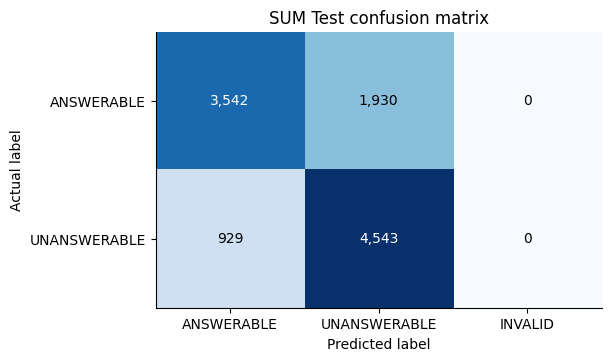

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,5472,3542,1930,0,35.27%,35.27%
UNANSWERABLE,5472,4543,929,0,16.98%,16.98%


There were **1,930 false positives** (35.27% of answerable questions) and **929 false negatives** (16.98% of unanswerable questions). Of the true UNANSWERABLE rows, 0 additionally received INVALID responses and count as missed positives in recall.

,Row index,Pair ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,1,29320,Let \( a \) and \( b \) be positive integers s...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE\n',False
False negative,29,8705,What is the sum of all four-digit odd integers...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE\n',False


**Categories with no recorded examples:** INVALID.

In [4]:
show_evaluation('SUM Test', sum_metrics, sum_matrix)
show_class_errors(sum_matrix)
display(Markdown(interpret_errors(sum_matrix)))
show_examples(sum_predictions, 'pair_id')

## 4. UMWP Results & Analysis

UMWP is an external mathematical word problem benchmark. The analysis uses the complete saved UMWP run.

The examples use the same selection rule as SUM Test.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP,"5,200",0.868462,0.935851,0.791154,0.857441,0 (0.00%)


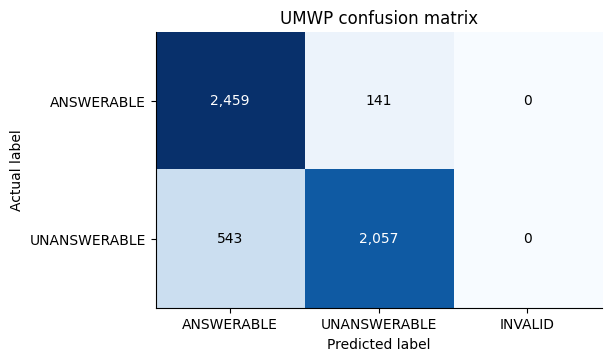

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2459,141,0,5.42%,5.42%
UNANSWERABLE,2600,2057,543,0,20.88%,20.88%


There were **141 false positives** (5.42% of answerable questions) and **543 false negatives** (20.88% of unanswerable questions). Of the true UNANSWERABLE rows, 0 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,6,7,The Razorback shop makes $ 210 dollars off eac...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE\n',False
False negative,2603,2504,Dave had 17 apps and 21 files on his phone. Af...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE\n',False


**Categories with no recorded examples:** INVALID.

In [5]:
show_evaluation('UMWP', umwp_metrics, umwp_matrix)
show_class_errors(umwp_matrix)
display(Markdown(interpret_errors(umwp_matrix)))
show_examples(umwp_predictions, 'id')

## 5. Dataset Comparison & Interpretation

Rates use each dataset's full run as the denominator for accuracy, INVALID rate, and prediction shares. Precision, recall and F1 use the UNANSWERABLE class. The metric chart shows INVALID separately because its scale is much smaller.

,ANSWERABLE,UNANSWERABLE,INVALID
Dataset,,,
SUM Test,4471 (40.85%),6473 (59.15%),0 (0.00%)
UMWP,3002 (57.73%),2198 (42.27%),0 (0.00%)


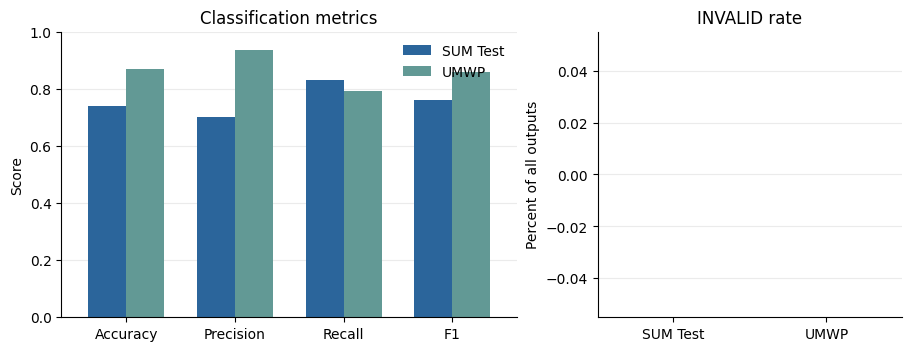

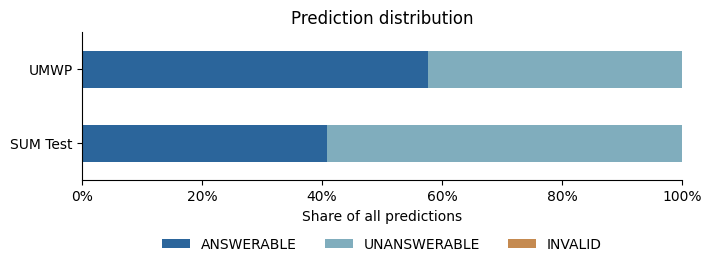

In [6]:
evaluations = {'SUM Test': (sum_metrics, sum_matrix), 'UMWP': (umwp_metrics, umwp_matrix)}
metric_rates = pd.DataFrame({
    name: {label: metrics[key] for label, key in METRICS.items()}
    for name, (metrics, _) in evaluations.items()
})
metric_rates.index = ['Accuracy', 'Precision', 'Recall', 'F1']
invalid_rates = pd.Series({name: metrics['invalid_rate'] for name, (metrics, _) in evaluations.items()})
prediction_counts = pd.DataFrame({
    name: matrix.sum(axis=0) for name, (_, matrix) in evaluations.items()
}).T
prediction_shares = prediction_counts.div(prediction_counts.sum(axis=1), axis=0)
display((prediction_counts.astype(str) + ' (' + prediction_shares.map('{:.2%}'.format) + ')')
        .rename_axis('Dataset'))

colors = ['#2b659b', '#629995']
fig, (ax_metrics, ax_invalid) = plt.subplots(
    1, 2, figsize=(9, 3.4), width_ratios=[3, 2], layout='constrained',
)
metric_rates.plot.bar(ax=ax_metrics, color=colors, rot=0, width=0.7)
ax_metrics.set(ylim=(0, 1), ylabel='Score', title='Classification metrics')
ax_metrics.legend(frameon=False, loc='upper right')
ax_invalid.bar(invalid_rates.index, invalid_rates * 100, color=colors)
ax_invalid.set(ylabel='Percent of all outputs', title='INVALID rate')
for ax in (ax_metrics, ax_invalid):
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 2.5), layout='constrained')
prediction_shares.plot.barh(ax=ax, stacked=True, color=['#2b659b', '#80adbd', '#c58a50'])
ax.set(xlim=(0, 1), xlabel='Share of all predictions', ylabel='', title='Prediction distribution')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.show()
plt.close(fig)

In [7]:
observations = []
for name, (metrics, matrix) in evaluations.items():
    actual_share = matrix.loc['UNANSWERABLE'].sum() / matrix.values.sum()
    predicted_share = prediction_shares.loc[name, 'UNANSWERABLE']
    precision = metrics['precision_unanswerable']
    recall = metrics['recall_unanswerable']
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    observations.append(
        f'On {name}, **{predicted_share:.2%}** of outputs were UNANSWERABLE '
        f'against an actual UNANSWERABLE share of {actual_share:.2%}. '
        f'Precision was **{precision:.2%}** and recall was **{recall:.2%}**, '
        f'with {fp:,} false positives and {fn:,} false negatives.'
    )
precision_gap = (umwp_metrics['precision_unanswerable'] - sum_metrics['precision_unanswerable']) * 100
recall_gap = (umwp_metrics['recall_unanswerable'] - sum_metrics['recall_unanswerable']) * 100
display(Markdown(
    ' '.join(observations) + ' Relative to SUM Test, UMWP changed UNANSWERABLE '
    f'precision by {precision_gap:+.2f} percentage points and recall by '
    f'{recall_gap:+.2f} percentage points. '
    'These differences describe the saved runs under the recorded prompt and decoding settings.'
))

On SUM Test, **59.15%** of outputs were UNANSWERABLE against an actual UNANSWERABLE share of 50.00%. Precision was **70.18%** and recall was **83.02%**, with 1,930 false positives and 929 false negatives. On UMWP, **42.27%** of outputs were UNANSWERABLE against an actual UNANSWERABLE share of 50.00%. Precision was **93.59%** and recall was **79.12%**, with 141 false positives and 543 false negatives. Relative to SUM Test, UMWP changed UNANSWERABLE precision by +23.40 percentage points and recall by -3.91 percentage points. These differences describe the saved runs under the recorded prompt and decoding settings.